<h1 align="center"><font color="red">Quick start skforecast</font></h1>

<font color="pink">Senior Data Scientist/AI Engineering.: Dr. Eddy Giusepe Chirinos Isidro</font>

Bem-vindo(a) a um guia rápido para usar o skforecast! Neste guia, forneceremos um exemplo de código que demonstra como criar, validar e otimizar um `previsor recursivo` de múltiplas etapas `ForecasterRecursive` usando o `skforecast`.

Um objeto `Forecaster` na biblioteca `skforecast` é um contêiner abrangente que fornece funcionalidades e métodos essenciais para treinar um modelo de previsão e gerar previsões para pontos futuros no tempo.

Caso necessite de documentação ou orientações mais detalhadas, pode consultar a secção de [Guias do Utilizador](https://skforecast.org/latest/user_guides/table-of-contents).

Sem mais delongas, vamos ao exemplo de código!

## <font color="gree">Libraries and Data</font>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error
from skforecast.datasets import load_demo_dataset
from skforecast.preprocessing import RollingFeatures
from skforecast.recursive import ForecasterRecursive
from skforecast.model_selection import TimeSeriesFold
from skforecast.model_selection import backtesting_forecaster
from skforecast.model_selection import grid_search_forecaster
from skforecast.plot import set_dark_theme


Os dados são o gasto mensal, em dólares australianos, do sistema de saúde da Austrália com `corticosteroides`, de julho de 1991 a junho de 2008.

O objeto `data` é uma `Series` do pandas:

* `índice`: datas no início de cada mês (Freq: MS)

* `valores` (y): gasto daquele mês

* tamanho: 204 observações (17 anos × 12 meses)



O corte fica assim: `treino` até junho de 2005 (`168 meses`) e `teste` de julho de 2005 a junho de 2008 (`36 meses`). A série tem tendência de alta e sazonalidade anual, por isso o skforecast usa ela no guia rápido.

In [2]:
# Download data:
data = load_demo_dataset()
data.head(5) # MS: Month Start

╭────────────────────────────────────── h2o ───────────────────────────────────────╮
│ Description:                                                                     │
│ Monthly expenditure ($AUD) on corticosteroid drugs that the Australian health    │
│ system had between 1991 and 2008.                                                │
│                                                                                  │
│ Source:                                                                          │
│ Hyndman R (2023). fpp3: Data for Forecasting: Principles and Practice(3rd        │
│ Edition). http://pkg.robjhyndman.com/fpp3package/,https://github.com/robjhyndman │
│ /fpp3package, http://OTexts.com/fpp3.                                            │
│                                                                                  │
│ URL:                                                                             │
│ https://raw.githubusercontent.com/skforecast/skforecast-                         │
│ datasets/main/data/h2o.csv                                                       │
│                                                                                  │
│ Shape: 204 rows                                                                  │
╰──────────────────────────────────────────────────────────────────────────────────╯

datetime
1991-07-01    0.429795
1991-08-01    0.400906
1991-09-01    0.432159
1991-10-01    0.492543
1991-11-01    0.502369
Freq: MS, Name: y, dtype: float64

Train dates : 1991-07-01 00:00:00 --- 2005-06-01 00:00:00  (n=168)
Test dates  : 2005-07-01 00:00:00 --- 2008-06-01 00:00:00  (n=36)


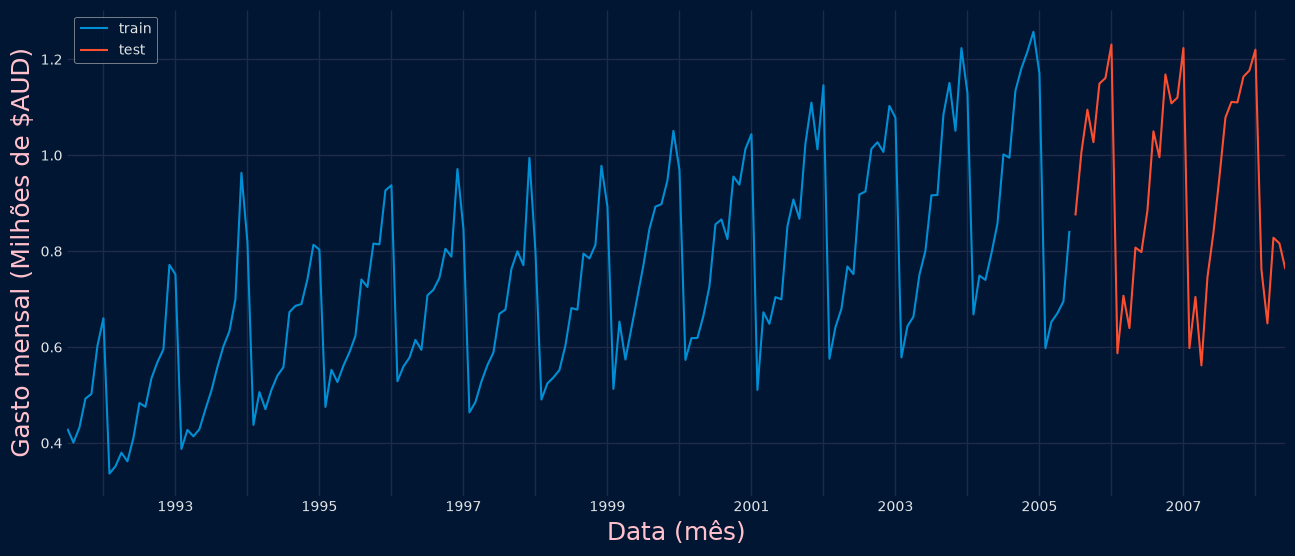

In [3]:
# Data partition train-test:
from turtle import color

from numpy import size


end_train = '2005-06-01 23:59:00'
print(
    f"Train dates : {data.index.min()} --- {data.loc[:end_train].index.max()}  " 
    f"(n={len(data.loc[:end_train])})"
)
print(
    f"Test dates  : {data.loc[end_train:].index.min()} --- {data.index.max()}  "
    f"(n={len(data.loc[end_train:])})"
)

# Plot:
set_dark_theme()
fig, ax = plt.subplots(figsize=(14, 6))
data.loc[:end_train].plot(ax=ax, label='train')
data.loc[end_train:].plot(ax=ax, label='test')
ax.set_xlabel('Data (mês)', color='pink', size=18)
ax.set_ylabel('Gasto mensal (Milhões de $AUD)', color='pink', size=18)
ax.legend()
plt.show()


## <font color="gree">Train a forecaster</font>

Vamos começar treinando um modelo de previsão!

Para um guia mais detalhado sobre como usar o recurso `ForecasterRecursive`, visite o [Guia do Usuário](https://skforecast.org/latest/user_guides/autoregressive-forecaster).


* `estimator`: Quem aprende a prever, ou seja, aprende a relação do passado. É o modelo de Machine Learning. O `skforecast` só organiza os dados e as previsões de vários passos; quem ajusta features → próximo y é o `estimator`.

Em nosso caso: `LGBMRegressor` (`LightGBM`, árvore com boosting). Serve qualquer regressor com API do `scikit-learn` (fit / predict): `LightGBM`, `XGBoost`, `RandomForest`, `regressão linear`, etc.
Sem `estimator` não há modelo. Sem `lags` ou `window_features` não há preditores. Os dois lados são obrigatórios.


* `lags`: O passado virando colunas.
Modelos como `LightGBM` não entendem tempo. O `skforecast` cria uma matriz em que cada linha é um mês e as colunas são valores anteriores.
`lags = 15` significa: use os 15 meses imediatamente anteriores para prever o mês atual.

`Por que importa`: é assim que a dependência temporal entra no modelo. Nesta série mensal com sazonalidade anual, `15 lags` cobrem um `ano + 3 meses`, então o modelo pode ver o mesmo período do ano passado.


* `window_features`: Resumo da janela recente.
Lags são valores crus (`y` de 1 mês atrás, 2 meses atrás . . .). `window_features` cria estatísticas desses valores passados e também as usa como preditores.

Isso adiciona uma coluna: a `média` dos últimos 10 meses.

     - `stats=['mean']` → média móvel
     - `window_sizes=10` → janela de 10 observações (aqui, 10 meses)

Serve para capturar o nível/tendência local. Um lag isolado oscila; a média de 10 meses suaviza e mostra se o gasto está alto ou baixo no período recente.

`Não é variável exógena` (calendário, feriado, preço). É um resumo da própria série.


In [4]:
# Create and fit a recursive multi-step forecaster (ForecasterRecursive):
forecaster = ForecasterRecursive(
                 estimator       = LGBMRegressor(random_state=123, # Resultado reproduzível
                                                 verbose=-1 # Sem log de treino
                                                ),
                 lags            = 15, # lags = [1, 2, 3, 12]  só esses (útil se só alguns atrasos importam)
                 window_features = RollingFeatures(stats=['mean'], window_sizes=10)
             )

forecaster.fit(y=data.loc[:end_train])
forecaster


=================== 
ForecasterRecursive 
=================== 
Estimator: LGBMRegressor 
Lags: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15] 
Window features: ['roll_mean_10'] 
Calendar features: None 
Window size: 15 
Series name: y 
Exogenous included: False 
Exogenous names: None 
Categorical features: auto 
Transformer for y: None 
Transformer for exog: None 
Weight function included: False 
Differentiation order: None 
Drop NaN from series: False 
Training range: [Timestamp('1991-07-01 00:00:00'), Timestamp('2005-06-01 00:00:00')] 
Training index type: DatetimeIndex 
Training index frequency: <MonthBegin> 
Estimator parameters: 
    {'boosting_type': 'gbdt', 'class_weight': None, 'colsample_bytree': 1.0,
    'importance_type': 'split', 'learning_rate': 0.1, 'max_depth': -1,
    'min_child_samples': 20, 'min_child_weight': 0.001, 'min_split_gain': 0.0,
    'n_estimators': 100, 'n_jobs': None, 'num_leaves': 31, 'objective': None,
    'random_state': 123, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0,
    'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbose': -1} 
fit_kwargs: {} 
Creation date: 2026-10-14 23:33:53 
Last fit date: 2026-10-14 23:33:53 
Skforecast version: 0.26.0 
Python version: 3.13.7 
Forecaster id: None

## <font color="gree">Prediction</font>

Após o treinamento do modelo de previsão, o método `predict` pode ser usado para fazer previsões para o futuro n steps.

In [5]:
# Predict:
predictions = forecaster.predict(steps=len(data.loc[end_train:]))
predictions.head(3)

2005-07-01    1.026507
2005-08-01    1.042429
2005-09-01    1.116730
Freq: MS, Name: pred, dtype: float64

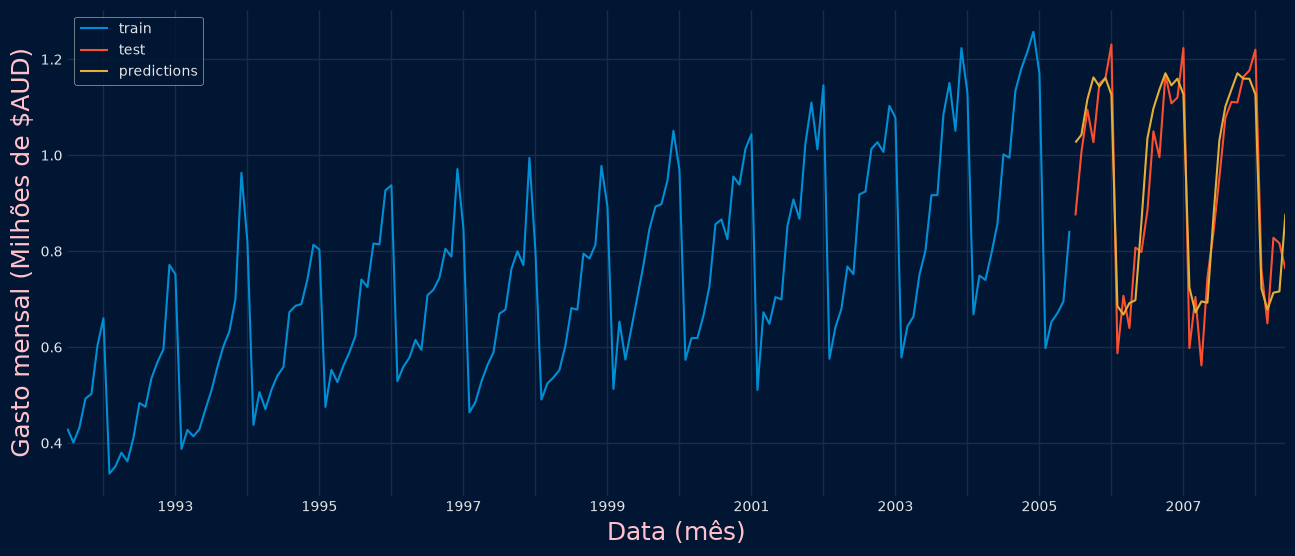

In [10]:
# Plot predictions:
fig, ax = plt.subplots(figsize=(14, 6))
data.loc[:end_train].plot(ax=ax, label='train')
data.loc[end_train:].plot(ax=ax, label='test')
predictions.plot(ax=ax, label='predictions')
ax.set_xlabel('Data (mês)', color='pink', size=18)
ax.set_ylabel('Gasto mensal (Milhões de $AUD)', color='pink', size=18)
ax.legend()
plt.show()


In [12]:
# Prediction error on test data:
error_mse = mean_squared_error(
                y_true = data.loc[end_train:], # Test real
                y_pred = predictions # Previsão
            )

print(f"Mean Squared Error (MSE): {error_mse}")

Mean Squared Error (MSE): 0.006632513357651682


Aqui o MSE sozinho é mais um `índice de qualidade` do que um gasto interpretável.

$$ \mathrm{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 $$


Para falar na mesma escala do gráfico (milhões de AUD), usa-se a raiz:

$$ \mathrm{RMSE} = \sqrt{\mathrm{MSE}} \approx 0.081 $$

Isso sim é “em média, o modelo erra cerca de 0,08 milhão de AUD por mês” (~80 mil AUD), com a ressalva de que outliers puxam esse número.

## <font color="gree">Backtesting: forecaster validation</font>

Em previsão de séries temporais, `backtesting` refere-se ao processo de validação de um modelo preditivo usando dados históricos. A técnica envolve voltar no tempo, passo a passo, para avaliar quão bem o modelo teria performado se tivesse sido usado para fazer previsões naquele período. O `backtesting` é uma forma de validação cruzada aplicada a períodos anteriores da série temporal.
 
O `backtesting` pode ser feito utilizando uma variedade de técnicas, como divisões simples em treino-teste ou métodos mais sofisticados como janelas deslizantes (`“rolling windows”`) ou janelas expansivas (`“expanding windows”`). A escolha do método depende das necessidades específicas da análise e das características dos dados da série temporal. Para documentação mais detalhada sobre backtesting, consulte: [User guide Backtesting forecaster](https://skforecast.org/latest/user_guides/backtesting).

In [13]:
# Backtesting:
cv = TimeSeriesFold(
         steps              = 10,
         initial_train_size = len(data.loc[:end_train]), # 168 meses até jun/2005
         refit              = True,
         fixed_train_size   = False # Janela expansiva 
     )

metric, predictions_backtest = backtesting_forecaster(
                                   forecaster    = forecaster,
                                   y             = data,
                                   cv            = cv,
                                   metric        = 'mean_squared_error',
                                   verbose       = True,
                               )

display(metric)
predictions_backtest

Information of folds
--------------------
Number of observations used for initial training: 168
Number of observations used for backtesting: 36
    Number of folds: 4
    Number skipped folds: 0 
    Number of steps per fold: 10
    Number of steps to exclude between last observed data (last window) and predictions (gap): 0
    Last fold only includes 6 observations.

Fold: 0
    Training:   1991-07-01 00:00:00 -- 2005-06-01 00:00:00  (n=168)
    Validation: 2005-07-01 00:00:00 -- 2006-04-01 00:00:00  (n=10)
Fold: 1
    Training:   1991-07-01 00:00:00 -- 2006-04-01 00:00:00  (n=178)
    Validation: 2006-05-01 00:00:00 -- 2007-02-01 00:00:00  (n=10)
Fold: 2
    Training:   1991-07-01 00:00:00 -- 2007-02-01 00:00:00  (n=188)
    Validation: 2007-03-01 00:00:00 -- 2007-12-01 00:00:00  (n=10)
Fold: 3
    Training:   1991-07-01 00:00:00 -- 2007-12-01 00:00:00  (n=198)
    Validation: 2008-01-01 00:00:00 -- 2008-06-01 00:00:00  (n=6)



  0%|          | 0/4 [00:00<?, ?it/s]

,mean_squared_error
0,0.006816


,fold,pred
2005-07-01,0,1.026507
2005-08-01,0,1.042429
2005-09-01,0,1.116730
2005-10-01,0,1.162179
2005-11-01,0,1.143455
2005-12-01,0,1.160991
2006-01-01,0,1.126347
2006-02-01,0,0.685447
2006-03-01,0,0.667809
2006-04-01,0,0.691714


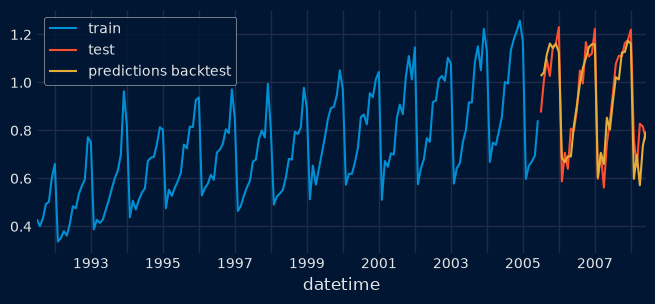

In [14]:
# Plot predictions:
fig, ax = plt.subplots(figsize=(7, 3))
data.loc[:end_train].plot(ax=ax, label='train')
data.loc[end_train:].plot(ax=ax, label='test')
predictions_backtest['pred'].plot(ax=ax, label='predictions backtest')
ax.legend();

In [ ]:
# Grid search hyperparameter and lags
# ==============================================================================
# Estimator hyperparameters
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, 15]
}

# Lags used as predictors
lags_grid = [3, 10, [1, 2, 3, 20]]

# Folds
cv = TimeSeriesFold(
         steps              = 10,
         initial_train_size = len(data.loc[:end_train]),
         refit              = False,
     )

results_grid = grid_search_forecaster(
                   forecaster  = forecaster,
                   y           = data,
                   param_grid  = param_grid,
                   lags_grid   = lags_grid,
                   cv          = cv,
                   metric      = 'mean_squared_error',
                   return_best = True,
               )

In [ ]:
# Grid results
# ==============================================================================
results_grid

In [ ]:
# Print forecaster information
# ==============================================================================
forecaster